# LIDC-IDRI: Exploração e Análise de Nódulos Pulmonares

Abordagem usando `pylidc` para carregar e processar dados de CT scans com anotações de múltiplos radiólogos.

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    LIDC-IDRI — Lung Image Database Consortium
  </h1>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    The reference dataset for lung nodule detection
  </h3>

  <p>
    O LIDC-IDRI é o dataset mais citado em deteção e classificação de nódulos pulmonares. Foi criado por 7 instituições académicas americanas, em colaboração com a <em>Foundation for the National Institutes of Health</em> e a <em>National Cancer Institute</em>.
  </p>

  <p>
    Ao contrário do LNDb- que é de uma única instituição (CHUSJ, Porto) e usa uma metodologia <em>single-blind</em>- o LIDC-IDRI foi anotado por <strong>4 radiotorácicos experientes</strong> em duas fases: uma primeira leitura cega (<em>blinded-read</em>) e uma segunda fase não-cega (<em>unblinded-read</em>), em que cada radiologista teve acesso às marcações anonimizadas dos outros três.
  </p>

  <p>
    Este notebook faz uma análise exploratória inicial do LIDC-IDRI, com o objetivo de extrair uma tabela de nódulos e de identificar as diferenças estruturais face ao LNDb.
  </p>

</div>

## Setup

Importamos as bibliotecas habituais e o `pylidc`, que lê os XMLs oficiais do LIDC e constrói uma base de dados SQLite local. Isto é essencial porque os XMLs originais são difíceis de consultar diretamente.

In [1]:
import pylidc as pl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from pathlib import Path

# Configuração do pylidc (ver .pylidcrc)
# O pylidc lê o ficheiro ~/.pylidcrc, que tem de apontar para a pasta dos XMLs
#print("Pylidc config:", pl.config)

# Quantos scans/pacientes temos disponíveis?
n_scans = pl.query(pl.Scan).count()
n_patients = pl.query(pl.Scan.patient_id).distinct().count()
n_annotations = pl.query(pl.Annotation).count()

print(f"Scans (séries de TC): {n_scans}")
print(f"Pacientes únicos:     {n_patients}")
print(f"Anotações totais:     {n_annotations}")

"""Silencia os prints do pylidc durante o clustering, que são muitos e não são úteis neste caso"""
from contextlib import redirect_stdout
import io

def cluster_annotations_silent(scan):
    with redirect_stdout(io.StringIO()):
        return scan.cluster_annotations()

Scans (séries de TC): 1018
Pacientes únicos:     1010
Anotações totais:     6859


## Ler um scan com `pylidc`

Antes de escalar para o dataset inteiro, confirmamos que a biblioteca funciona no nosso ambiente. Escolhemos o `LIDC-IDRI-0001` porque é pequeno e está sempre presente.

In [2]:
patient_id = 'LIDC-IDRI-0003'
scan = pl.query(pl.Scan).filter(pl.Scan.patient_id == patient_id).first()

if scan is None:
    print(f"Scan  não encontrado")
else:
    print(f"  patient_id:  {scan.patient_id}")
    print(f"  study_uid:   {scan.study_instance_uid[:40]}...")
    print(f"  series_uid:  {scan.series_instance_uid[:40]}...")
    print(f"  slice_thickness: {scan.slice_thickness} mm")
    print(f"  pixel_spacing:   {scan.pixel_spacing} mm")
    print(f"  n annotations:   {len(scan.annotations)}")

  patient_id:  LIDC-IDRI-0003
  study_uid:   1.3.6.1.4.1.14519.5.2.1.6279.6001.101370...
  series_uid:  1.3.6.1.4.1.14519.5.2.1.6279.6001.170706...
  slice_thickness: 2.5 mm
  pixel_spacing:   0.820312 mm
  n annotations:   13


## Explorar Anotações

**Cada objeto `Annotation` representa a leitura de um radiologista sobre um nódulo.** Como cada nódulo foi anotado por até 4 radiologistas, temos de agrupar as anotações que se referem ao **mesmo nódulo físico**.

O `pylidc` implementa isso através de `scan.cluster_annotations()`, que devolve uma lista de listas: cada sublista contém as anotações (1 a 4) que correspondem ao mesmo nódulo.

In [3]:
clusters = scan.cluster_annotations()

print(f"Nódulos únicos: {len(clusters)}")
print(f"Anotações totais: {len(scan.annotations)}")
print()

for i, cluster in enumerate(clusters):
    print(f"  Nódulo {i}: {len(cluster)} anotações")
    for ann in cluster:
        mal = ann.malignancy
        diam = ann.diameter
        print(f"    - id={ann.id}  malignidade={mal}  diâmetro={diam:.1f} mm")

Nódulos únicos: 4
Anotações totais: 13

  Nódulo 0: 1 anotações
    - id=102  malignidade=2  diâmetro=31.7 mm
  Nódulo 1: 4 anotações
    - id=90  malignidade=5  diâmetro=30.4 mm
    - id=93  malignidade=5  diâmetro=30.1 mm
    - id=98  malignidade=3  diâmetro=28.0 mm
    - id=99  malignidade=4  diâmetro=35.5 mm
  Nódulo 2: 4 anotações
    - id=91  malignidade=4  diâmetro=13.4 mm
    - id=95  malignidade=4  diâmetro=11.9 mm
    - id=97  malignidade=3  diâmetro=13.2 mm
    - id=100  malignidade=2  diâmetro=14.8 mm
  Nódulo 3: 4 anotações
    - id=92  malignidade=4  diâmetro=14.7 mm
    - id=94  malignidade=5  diâmetro=14.3 mm
    - id=96  malignidade=3  diâmetro=15.3 mm
    - id=101  malignidade=2  diâmetro=15.6 mm


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h3 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px;">
    As 9 características subjetivas (por radiologista)
  </h3>

  <p>
    Para cada nódulo ≥ 3 mm, cada um dos 4 radiotorácicos avaliou
    subjetivamente as seguintes características. São <strong>avaliações
    individuais</strong> — ou seja, o mesmo nódulo tem 4 conjuntos de
    valores (um por radiologista).
  </p>

  <table style="width: 100%; border-collapse: collapse; margin-top: 15px; color: #f0f0f0;">
    <thead>
      <tr style="background-color: #c25719; color: #ffffff;">
        <th style="padding: 8px; border: 1px solid #444; text-align: left;">Característica</th>
        <th style="padding: 8px; border: 1px solid #444; text-align: left;">Escala</th>
        <th style="padding: 8px; border: 1px solid #444; text-align: left;">Significado</th>
      </tr>
    </thead>
    <tbody>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><code>malignancy</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1–5</td>
        <td style="padding: 8px; border: 1px solid #444;">Probabilidade global de cancro</td>
      </tr>
      <tr style="background-color: #00183a40;">
        <td style="padding: 8px; border: 1px solid #444;"><code>subtlety</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1–5</td>
        <td style="padding: 8px; border: 1px solid #444;">Dificuldade em detetar o nódulo</td>
      </tr>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><code>internalStructure</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1–4</td>
        <td style="padding: 8px; border: 1px solid #444;">Sólido / subsólido / parte-sólido / cavitário</td>
      </tr>
      <tr style="background-color: #00183a40;">
        <td style="padding: 8px; border: 1px solid #444;"><code>calcification</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1–6</td>
        <td style="padding: 8px; border: 1px solid #444;">Padrão de calcificação (1 = popcorn benigno, 6 = sem calcificação)</td>
      </tr>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><code>sphericity</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1–5</td>
        <td style="padding: 8px; border: 1px solid #444;">Semelhança com esfera</td>
      </tr>
      <tr style="background-color: #00183a40;">
        <td style="padding: 8px; border: 1px solid #444;"><code>margin</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1–5</td>
        <td style="padding: 8px; border: 1px solid #444;">Nitidez da margem</td>
      </tr>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><code>lobulation</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1–5</td>
        <td style="padding: 8px; border: 1px solid #444;">Contorno ondulado (lobulado)</td>
      </tr>
      <tr style="background-color: #00183a40;">
        <td style="padding: 8px; border: 1px solid #444;"><code>spiculation</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1–5</td>
        <td style="padding: 8px; border: 1px solid #444;">Espículas radiantes (sunburst sign)</td>
      </tr>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><code>texture</code></td>
        <td style="padding: 8px; border: 1px solid #444;">1–5</td>
        <td style="padding: 8px; border: 1px solid #444;">Textura (1 = GGO, 5 = sólido)</td>
      </tr>
    </tbody>
  </table>

  <h3 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 25px;">
    Métricas geométricas (calculadas pelo pylidc)
  </h3>

  <table style="width: 100%; border-collapse: collapse; color: #f0f0f0;">
    <thead>
      <tr style="background-color: #c25719; color: #ffffff;">
        <th style="padding: 8px; border: 1px solid #444; text-align: left;">Atributo</th>
        <th style="padding: 8px; border: 1px solid #444; text-align: left;">Unidade</th>
        <th style="padding: 8px; border: 1px solid #444; text-align: left;">Significado</th>
      </tr>
    </thead>
    <tbody>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><code>diameter</code></td>
        <td style="padding: 8px; border: 1px solid #444;">mm</td>
        <td style="padding: 8px; border: 1px solid #444;">Diâmetro maior do nódulo</td>
      </tr>
      <tr style="background-color: #00183a40;">
        <td style="padding: 8px; border: 1px solid #444;"><code>centroid</code></td>
        <td style="padding: 8px; border: 1px solid #444;">(x, y, z) em píxeis</td>
        <td style="padding: 8px; border: 1px solid #444;">Centroide do nódulo no volume</td>
      </tr>
      <tr>
        <td style="padding: 8px; border: 1px solid #444;"><code>volume</code></td>
        <td style="padding: 8px; border: 1px solid #444;">mm³</td>
        <td style="padding: 8px; border: 1px solid #444;">Volume do nódulo (via <code>pylidc.utils.volume</code>)</td>
      </tr>
    </tbody>
  </table>

  <p style="margin-top: 20px; font-size: 0.9em; color: #cccccc;">
    <strong>Nota:</strong> os valores subjetivos são avaliações
    <strong>individuais por radiologista</strong>, não valores de consenso.
    Um nódulo com 4 anotações tem 4 linhas de características- cabe ao
    pipeline decidir como as agregar.
  </p>

</div>

In [4]:
# seleção de 5 nódulos de scans diferentes, para mostrar como as características variam na prática.
exemplos = []
scans_alvo = ['LIDC-IDRI-0001', 'LIDC-IDRI-0003',
              'LIDC-IDRI-0004', 'LIDC-IDRI-0005', 'LIDC-IDRI-0008']

for pid in scans_alvo:
    s = pl.query(pl.Scan).filter(pl.Scan.patient_id == pid).first()

   
    clusters_s = s.cluster_annotations()

    ann = clusters_s[0][0]  # primeiro nódulo, primeiro radiologista

    exemplos.append({
        'scan_id':        pid,
        'diâmetro (mm)':  round(ann.diameter, 1),
        'malignancy':     ann.malignancy,
        'subtlety':       ann.subtlety,
        'internalStruct': ann.internalStructure,
        'calcification':  ann.calcification,
        'sphericity':     ann.sphericity,
        'margin':         ann.margin,
        'lobulation':     ann.lobulation,
        'spiculation':    ann.spiculation,
        'texture':        ann.texture,
    })

df_exemplos = pd.DataFrame(exemplos)
df_exemplos

,scan_id,diâmetro (mm),malignancy,subtlety,internalStruct,calcification,sphericity,margin,lobulation,spiculation,texture
0,LIDC-IDRI-0001,32.2,5,5,1,6,3,3,3,4,5
1,LIDC-IDRI-0003,31.7,2,1,1,6,5,2,1,1,1
2,LIDC-IDRI-0004,6.3,2,3,1,6,4,5,1,1,5
3,LIDC-IDRI-0005,6.3,3,3,1,6,4,5,1,1,5
4,LIDC-IDRI-0008,8.2,3,3,1,6,4,4,1,1,5


## Categorias de anotação do LIDC

O protocolo original do LIDC-IDRI distingue três tipos de achado: nódulo ≥ 3 mm, nódulo < 3 mm e não-nódulo ≥ 3 mm. O `pylidc` só cria objetos `Annotation` para a primeira categoria- as restantes existem nos XMLs originais mas não são carregadas para a base de dados SQLite.

Note-se que o critério de 3 mm do protocolo refere-se ao maior diâmetro in-plane, não ao diâmetro equivalente esférico — uma distinção que se revelará relevante na verificação abaixo.

In [5]:
n_scans = pl.query(pl.Scan).count()
n_annotations = pl.query(pl.Annotation).count()

# extrair diâmetro e malignidade de cada anotação
diametros = []
malignidades = []
for a in pl.query(pl.Annotation):
    diametros.append(a.diameter)
    malignidades.append(a.malignancy)

diametros = np.array([d for d in diametros if d is not None])

n_ge_3mm = (diametros >= 3.0).sum()
pct_ge_3mm = 100 * n_ge_3mm / len(diametros)
n_com_malig = sum(1 for m in malignidades if m is not None)

print(f"Scans LIDC:                              {n_scans}")
print(f"Anotações acessíveis via pylidc:         {n_annotations}")
print()
print(f"Anotações com diâmetro >= 3mm:           {n_ge_3mm}/{len(diametros)} ({pct_ge_3mm:.1f}%)")
print(f"Diâmetro mínimo:                         {diametros.min():.2f}")
print(f"Anotações com malignidade avaliada:      {n_com_malig}/{n_annotations} "
      f"({100*n_com_malig/n_annotations:.1f}%)")

Scans LIDC:                              1018
Anotações acessíveis via pylidc:         6859

Anotações com diâmetro >= 3mm:           6854/6859 (99.9%)
Diâmetro mínimo:                         2.54
Anotações com malignidade avaliada:      6859/6859 (100.0%)


**Conclusão:** o `pylidc` expõe 6859 anotações em 1018 séries LIDC, todas com malignidade avaliada. Destas, 6854 (99.9%) têm diâmetro equivalente ≥ 3 mm. As 5 abaixo do limiar (mínimo 2.54 mm) não são erros: resultam da diferença entre o critério do protocolo LIDC- o maior diâmetro in-plane- e o cálculo do `pylidc`, que reporta o diâmetro equivalente esférico a partir do volume do contorno. O artigo fundacional do dataset já previa explicitamente esta situação, notando que *"lesions marked by a radiologist as nodule ≥ 3 mm but with outlines constructed by the radiologist that yield a greatest diameter less than 3 mm are possible"* (Armato et al., 2011). O conjunto exposto pelo `pylidc` corresponde, portanto, aos nódulos utilizáveis para classificação, sem necessidade de filtragem adicional.

## Cobertura de malignidade (quantos nódulos têm as 4 anotações?)

**Quantos nódulos têm o "label completo" (4 radiólogos) vs. quantos têm menos?**

Estratégia: para cada cluster de anotações, contar em quantos radiologistas o campo `malignancy` está preenchido (não é `NaN` nem `-1`).

In [6]:
from collections import Counter

cobertura = Counter()  # {n_rad_que_anotaram: nº de nódulos}
total_nodulos = 0

for scan in pl.query(pl.Scan):
    for cluster in cluster_annotations_silent(scan):
        cobertura[len(cluster)] += 1
        total_nodulos += 1

print(f"Total de nódulos: {total_nodulos}")
print()
print("Distribuição de cobertura (nº de radiologistas por nódulo):")
for k in sorted(cobertura, reverse=True):
   
    print(f"  {k} radiologista(s): {cobertura[k]:5d} nódulos")

Total de nódulos: 2651

Distribuição de cobertura (nº de radiologistas por nódulo):
  8 radiologista(s):     1 nódulos
  7 radiologista(s):     3 nódulos
  6 radiologista(s):     2 nódulos
  5 radiologista(s):     8 nódulos
  4 radiologista(s):   897 nódulos
  3 radiologista(s):   481 nódulos
  2 radiologista(s):   488 nódulos
  1 radiologista(s):   771 nódulos


O pylidc tem um bug conhecido no clustering: nódulos espacialmente próximos são por vezes fundidos num só cluster, resultando em grupos com **5, 6, 7 ou 8 anotações** (quando o máximo real é 4 radiologistas). Ainda não foram removidos estes casos, mas estão assinalados na tabela abaixo na coluna `cluster_suspeito` do DataFrame.

**Ideia:** excluir os clusters suspeitos (< 1%), porque não têm interpretação válida como um único nódulo.

**Discustir com o grupo!!**

Possível citação científica: Setio, A.A.A. et al. (2017), "Validation, comparison, and combination of algorithms for automatic detection of pulmonary nodules in computed tomography images: the LUNA16 challenge", Medical Image Analysis, vol. 42, pp. 1-13.

## Concordância entre radiologistas no LIDC

No LIDC, cada nódulo foi anotado por até 4 radiologistas em duas fases (uma cega e uma não-cega), pelo que o mesmo nódulo físico tem tipicamente várias avaliações de malignidade- uma por radiologista.

Se estas avaliações concordassem sempre, a agregação seria trivial. Não concordam. Esta secção quantifica a discordância em duas dimensões:

1. **Amplitude**- a diferença entre a classificação mais alta e a mais baixa que um nódulo recebeu (`max - min`), no intervalo 0–4.
2. **Gravidade**- se a discordância é apenas ruído de escala (diferença de 1 ponto) ou se é clínica, isto é, se um radiologista classificou o nódulo como benigno (1–2) e outro como maligno (4–5).

O objetivo é medir o ruído intrínseco do rótulo antes de decidirmos como o agregar, seguindo a mesma lógica que foi aplicada ao LNDb.

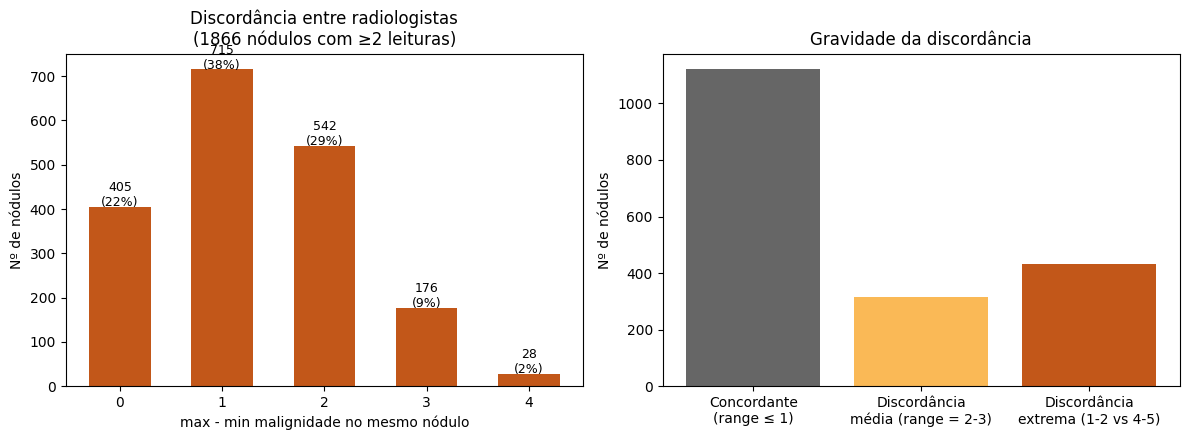

n = 1866 nódulos com ≥2 leituras
Concordância perfeita (range = 0): 405 (22%)
Discordância séria (range ≥ 2): 746 (40%)
Discordância extrema (1-2 vs 4-5): 431 (23%)


In [7]:
# Para cada nódulo (cluster), calcular a dispersão de malignidade entre radiologistas
dispersoes = []
for scan in pl.query(pl.Scan):
    clusters = cluster_annotations_silent(scan)
    for cluster in clusters:
        if len(cluster) > 4:  # ignora clusters bugados
            continue
        ratings = [a.malignancy for a in cluster if a.malignancy is not None]
        if len(ratings) >= 2:
            dispersoes.append({
                'n_raters': len(ratings),
                'min': min(ratings),
                'max': max(ratings),
                'range': max(ratings) - min(ratings),
            })

df_disp = pd.DataFrame(dispersoes)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Histograma do range
counts = df_disp['range'].value_counts().reindex(range(5), fill_value=0)
axes[0].bar(counts.index, counts.values, width=0.6, color='#c25719')
for x, n in zip(counts.index, counts.values):
    axes[0].text(x, n + 2, f"{n}\n({100*n/len(df_disp):.0f}%)",
                 ha='center', fontsize=9)
axes[0].set_xlabel("max - min malignidade no mesmo nódulo")
axes[0].set_ylabel("Nº de nódulos")
axes[0].set_title(f"Discordância entre radiologistas\n({len(df_disp)} nódulos com ≥2 leituras)")

# Discordância extrema: 1-2 vs 4-5
extremo = ((df_disp['min'] <= 2) & (df_disp['max'] >= 4)).sum()
axes[1].bar(['Concordante\n(range ≤ 1)', 'Discordância\nmédia (range = 2-3)',
             'Discordância\nextrema (1-2 vs 4-5)'],
            [(df_disp['range'] <= 1).sum(),
             ((df_disp['range'] >= 2) & ~((df_disp['min'] <= 2) & (df_disp['max'] >= 4))).sum(),
             extremo],
            color=['#666666', '#fab956', '#c25719'])
axes[1].set_ylabel("Nº de nódulos")
axes[1].set_title("Gravidade da discordância")
plt.tight_layout()
plt.show()

print(f"n = {len(df_disp)} nódulos com ≥2 leituras")
print(f"Concordância perfeita (range = 0): {(df_disp['range'] == 0).sum()} ({(df_disp['range'] == 0).mean():.0%})")
print(f"Discordância séria (range ≥ 2): {(df_disp['range'] >= 2).sum()} ({(df_disp['range'] >= 2).mean():.0%})")
print(f"Discordância extrema (1-2 vs 4-5): {extremo} ({extremo/len(df_disp):.0%})")

**Conclusão:** dos 1866 nódulos do LIDC com duas ou mais leituras, apenas 405 (22%) têm concordância perfeita entre radiologistas. Outros 715 (38%) diferem por um único ponto, o que numa escala ordinal de 5 valores está próximo do ruído. Os restantes 746 (40%) diferem por dois pontos ou mais — discordância substancial.

O número mais relevante é o da discordância extrema: 431 nódulos (23%) foram classificados como benignos (1–2) por um radiologista e como malignos (4–5) por outro.

**Implicações para o pipeline:** a magnitude da discordância justifica três decisões. Primeiro, agregar por nódulo em vez de escolher uma leitura arbitrária — caso contrário, o rótulo dependeria do acaso de qual radiologista foi registado primeiro. Segundo, usar a média, que absorve a dispersão em vez de a amplificar como o máximo faria. Terceiro, manter uma classe intermédia (indeterminado) na classificação final, porque a discordância entre radiologistas não afeta apenas a confiança do rótulo — afeta a própria definição de "benigno" e "maligno" para os casos limítrofes.

### Estruturar melhor isto 

## Processar Anotações

Extrair coordenadas e características de cada anotação para análise.

**Nota sobre o `radiologo_id`:** no LIDC, a identidade dos radiologistas não é rastreável entre scans. O que podemos fazer é numerar as anotações dentro de um cluster (1 a 4). Isto **não é equivalente** ao `RadID` do LNDb, que identifica consistentemente o mesmo radiologista em todos os scans.

In [8]:
def extrair_nodulos_lidc(scan, max_nodulos=None):
    """NOTA: clusters com mais de 4 anotações sinalizamos com
    `cluster_suspeito=True` para poderem ser filtrados depois."""
    registos = []
    clusters = scan.cluster_annotations()

    for nodulo_idx, cluster in enumerate(clusters):
        if max_nodulos and nodulo_idx >= max_nodulos:
            break

        suspeito = len(cluster) > 4  # detetar cluster com mais de 4 anotações (bug do pylidc)

        for radiologista_idx, ann in enumerate(cluster):
            x, y, z = ann.centroid
            registos.append({
                'dataset':            'LIDC-IDRI',
                'scan_id':            scan.patient_id,
                'nodulo_id':          nodulo_idx,
                'x':                  float(x),
                'y':                  float(y),
                'z':                  float(z),
                'diametro_mm':        float(ann.diameter) if ann.diameter is not None else np.nan,
                'categoria':          1,
                'malignidade_rating': ann.malignancy,
                'radiologo_id':       radiologista_idx + 1,
                'cluster_suspeito':   suspeito,
            })
    return registos


todos = []
for pid in ['LIDC-IDRI-0001', 'LIDC-IDRI-0002', 'LIDC-IDRI-0003',
            'LIDC-IDRI-0004', 'LIDC-IDRI-0005']:
    s = pl.query(pl.Scan).filter(pl.Scan.patient_id == pid).first()
    if s is None:
        continue
    todos.extend(extrair_nodulos_lidc(s))

df_amostra = pd.DataFrame(todos)

# se decidirmos remover os clusters suspeitos (com mais de 4 anotações), descomentar a linha abaixo
#df_amostra = df_amostra[~df_amostra['cluster_suspeito']] 


"QUAL DESTAS FORMAS ESTÁ CORRETA????"
print(f"Amostra limpa: {len(df_amostra)} anotações "
      f"({df_amostra['nodulo_id'].nunique()} nódulos únicos em "
      f"{df_amostra['scan_id'].nunique()} scans)")

n_nodulos = df_amostra.groupby(['scan_id', 'nodulo_id']).ngroups
print(f"Amostra: {len(df_amostra)} anotações ({n_nodulos} nódulos únicos em "
      f"{df_amostra['scan_id'].nunique()} scans)")

# Ver distribuição de anotações por nódulo- confirmação de que a lógica está certa
print("\nAnotações por nódulo:")
print(df_amostra.groupby(['scan_id', 'nodulo_id']).size().reset_index(name='n_anotacoes'))

df_amostra.head(10)

Amostra limpa: 32 anotações (4 nódulos únicos em 5 scans)
Amostra: 32 anotações (10 nódulos únicos em 5 scans)

Anotações por nódulo:
          scan_id  nodulo_id  n_anotacoes
0  LIDC-IDRI-0001          0            4
1  LIDC-IDRI-0002          0            2
2  LIDC-IDRI-0003          0            1
3  LIDC-IDRI-0003          1            4
4  LIDC-IDRI-0003          2            4
5  LIDC-IDRI-0003          3            4
6  LIDC-IDRI-0004          0            4
7  LIDC-IDRI-0005          0            4
8  LIDC-IDRI-0005          1            4
9  LIDC-IDRI-0005          2            1


,dataset,scan_id,nodulo_id,x,y,z,diametro_mm,categoria,malignidade_rating,radiologo_id,cluster_suspeito
0,LIDC-IDRI,LIDC-IDRI-0001,0,365.874473,315.048523,89.551688,32.205888,1,5,1,False
1,LIDC-IDRI,LIDC-IDRI-0001,0,367.850606,316.277254,89.728129,33.188692,1,5,2,False
2,LIDC-IDRI,LIDC-IDRI-0001,0,366.955527,316.133418,89.538755,31.959332,1,5,3,False
3,LIDC-IDRI,LIDC-IDRI-0001,0,366.502720,316.467900,89.801959,33.669337,1,4,4,False
4,LIDC-IDRI,LIDC-IDRI-0002,0,363.265779,345.634122,184.442801,30.023172,1,5,1,False
5,LIDC-IDRI,LIDC-IDRI-0002,0,359.058796,344.810442,185.646284,31.540171,1,4,2,False
6,LIDC-IDRI,LIDC-IDRI-0003,0,346.394690,368.923894,66.148673,31.664468,1,2,1,False
7,LIDC-IDRI,LIDC-IDRI-0003,1,349.583636,366.900000,75.232727,30.351544,1,5,1,False
8,LIDC-IDRI,LIDC-IDRI-0003,1,350.834008,367.080972,75.275304,30.117853,1,5,2,False
9,LIDC-IDRI,LIDC-IDRI-0003,1,350.614341,367.385659,75.242248,27.998968,1,3,3,False


Extrai a lista de nódulos de um scan LIDC-IDRI no esquema combinado.
Cada linha corresponde a UMA anotação (um radiologista).

## Visualizar um Nódulo

Confirmamos visualmente que os centroides e as máscaras correspondem a nódulos reais.

Loading dicom files ... This may take a moment.


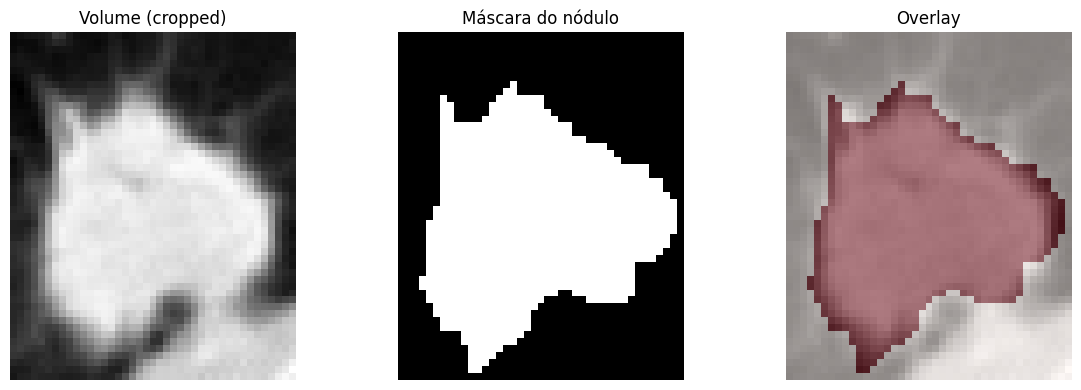

Diâmetro: 32.21 mm
Malignidade: 5
Textura: 5


In [9]:
scan = pl.query(pl.Scan).filter(pl.Scan.patient_id == 'LIDC-IDRI-0001').first()
clusters = scan.cluster_annotations()

if len(clusters) > 0:
    cluster = clusters[0]
    ann = cluster[0]  # primeira anotação do primeiro nódulo

    # Bounding box e máscara
    bbox = ann.bbox()
    volume = scan.to_volume()
    cropped = volume[bbox]
    mask = ann.boolean_mask()

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    slice_idx = cropped.shape[2] // 2

    axes[0].imshow(cropped[:, :, slice_idx], cmap='gray')
    axes[0].set_title('Volume (cropped)')
    axes[0].axis('off')

    axes[1].imshow(mask[:, :, slice_idx], cmap='gray')
    axes[1].set_title('Máscara do nódulo')
    axes[1].axis('off')

    axes[2].imshow(cropped[:, :, slice_idx], cmap='gray')
    axes[2].imshow(mask[:, :, slice_idx], cmap='Reds', alpha=0.5)
    axes[2].set_title('Overlay')
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

    print(f"Diâmetro: {ann.diameter:.2f} mm")
    print(f"Malignidade: {ann.malignancy}")
    print(f"Textura: {ann.texture}")

## EDA- Distribuição de diâmetro dos nódulos

O diâmetro é a variável mais diretamente ligada à decisão de tamanho de patch. No LIDC o diâmetro é calculado pelo pylidc a partir do contorno (`ann.diameter`), ao contrário do LNDb onde vem de um volume segmentado.

**O que esta distribuição decide:** o tamanho da patch de treino. Se a patch for demasiado pequena, corta os nódulos maiores; se for demasiado grande, o nódulo ocupa uma fração minúscula da imagem e o modelo perde capacidade de foco.

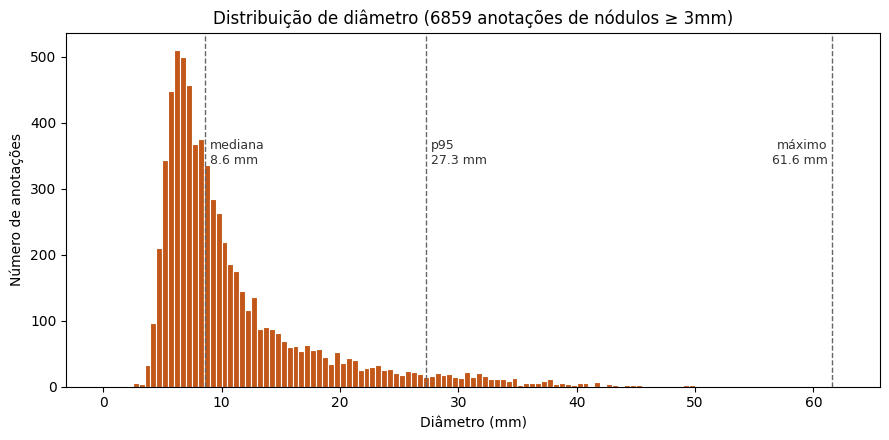

n = 6859
mediana = 8.65 mm
p95 = 27.29 mm
máx = 61.58 mm
min = 2.54 mm


In [10]:
# Recolher todos os diâmetros de nódulos >= 3mm (com malignidade) 
"""onde é que eu especifico que tem que te tamanho superior a 3mm?"""
diametros = []
for scan in pl.query(pl.Scan):
    for ann in scan.annotations:
        if ann.malignancy is not None and ann.diameter is not None:
            diametros.append(ann.diameter)

diametros = np.array(diametros)
p50, p95, dmax = np.percentile(diametros, [50, 95, 100])

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(diametros, bins=np.arange(0, diametros.max() + 1, 0.5),
        color='#c25719', edgecolor='white', linewidth=0.8)
top = ax.get_ylim()[1]
for val, name, align in [(p50, "mediana", "left"),
                          (p95, "p95", "left"),
                          (dmax, "máximo", "right")]:
    ax.axvline(val, color='#666666', linestyle='--', linewidth=1)
    offset = 0.4 if align == "left" else -0.4
    ax.text(val + offset, top*0.7, f"{name}\n{val:.1f} mm",
            ha=align, va='top', fontsize=9, color='#333333')
ax.set_xlabel("Diâmetro (mm)")
ax.set_ylabel("Número de anotações")
ax.set_title(f"Distribuição de diâmetro ({len(diametros)} anotações de nódulos ≥ 3mm)")
plt.tight_layout()
plt.show()

print(f"n = {len(diametros)}")
print(f"mediana = {p50:.2f} mm")
print(f"p95 = {p95:.2f} mm")
print(f"máx = {dmax:.2f} mm")
print(f"min = {diametros.min():.2f} mm")

**Conclusão:** a distribuição de diâmetro das 6859 anotações tem mediana 8.65 mm, p95 de 27.29 mm e máximo de 61.58 mm. A forma é fortemente assimétrica à direita: a maioria dos nódulos é pequena, mas existe uma cauda longa de nódulos grandes. O mínimo observado é 2.54 mm — os 5 casos abaixo de 3 mm já discutidos anteriormente, que resultam da diferença entre o critério in-plane do protocolo LIDC (Armato et al., 2011) e o diâmetro equivalente esférico calculado pelo pylidc.

Esta distribuição tem duas implicações para o pipeline:

**Tamanho da patch.** A amplitude de tamanhos- de 2.54 mm a 61.58 mm- torna problemática qualquer escolha de patch de tamanho fixo. O máximo de 61.58 mm é um outlier extremo: corresponde a menos de 1% das anotações, mas dimensionar a patch por ele significaria sacrificar resolução em todas as outras. Uma patch pequena corta a cauda de nódulos grandes; uma patch grande, dimensionada para os maiores, deixa os nódulos mais comuns a ocupar uma fração mínima da imagem. A literatura recente responde a este problema com abordagens multiescala, que extraem patches de tamanhos diferentes conforme o nódulo e os processam em ramos separados (Setio et al., 2017; Yang et al., 2023). Esta decisão fica em aberto até à fase de preprocessing.

**Necessidade de resampling.** Como o diâmetro está em milímetros mas as imagens têm spacing in-plane variável (tipicamente 0.5–0.8 mm), qualquer comparação entre nódulos de scans diferentes exige resampling para spacing isotrópico.

## EDA- Voxel spacing entre scans

O LIDC foi adquirido em 7 instituições com scanners diferentes, ao contrário do LNDb (1 instituição, 3 modelos Siemens). A heterogeneidade de spacing é o principal motivo pelo qual faz sentido resampling antes da extração de features.

**O que isto decide:** se vale a pena resamplear para spacing isotrópico, e para que valor. A resposta para o LNDb já foi "sim". Aqui queremos ver se o LIDC permite o mesmo alvo.

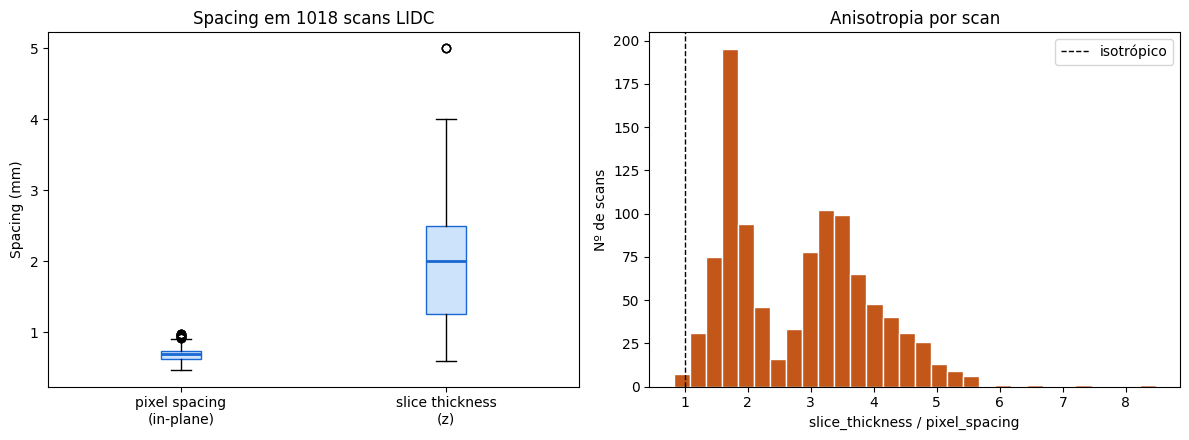

       pixel_spacing  slice_thickness  anisotropy
count       1018.000         1018.000    1018.000
mean           0.688            1.919       2.821
std            0.085            0.729       1.122
min            0.461            0.600       0.821
25%            0.625            1.250       1.778
50%            0.699            2.000       2.917
75%            0.742            2.500       3.556
max            0.977            5.000       8.477

Scans isotrópicos (ratio entre 0.95 e 1.05): 2


In [11]:
# Recolher spacing de todos os scans
spacings = []
for scan in pl.query(pl.Scan):
    spacings.append({
        'patient_id': scan.patient_id,
        'slice_thickness': scan.slice_thickness,
        'pixel_spacing': scan.pixel_spacing,
    })
df_spacing = pd.DataFrame(spacings)

# Anisotropia z/x
df_spacing['anisotropy'] = df_spacing['slice_thickness'] / df_spacing['pixel_spacing']

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Boxplot
axes[0].boxplot([df_spacing['pixel_spacing'].dropna(),
                 df_spacing['slice_thickness'].dropna()],
                tick_labels=['pixel spacing\n(in-plane)', 'slice thickness\n(z)'],
                patch_artist=True,
                boxprops=dict(facecolor='#cde2fb', edgecolor='#1967d2'),
                medianprops=dict(color='#1967d2', linewidth=2))
axes[0].set_ylabel("Spacing (mm)")
axes[0].set_title(f"Spacing em {len(df_spacing)} scans LIDC")

# Histograma de anisotropia
axes[1].hist(df_spacing['anisotropy'].dropna(), bins=30,
             color='#c25719', edgecolor='white')
axes[1].axvline(1.0, color='black', linestyle='--', linewidth=1, label='isotrópico')
axes[1].set_xlabel("slice_thickness / pixel_spacing")
axes[1].set_ylabel("Nº de scans")
axes[1].set_title("Anisotropia por scan")
axes[1].legend()
plt.tight_layout()
plt.show()

print(df_spacing[['pixel_spacing', 'slice_thickness', 'anisotropy']].describe().round(3))
print(f"\nScans isotrópicos (ratio entre 0.95 e 1.05): "
      f"{((df_spacing['anisotropy'] > 0.95) & (df_spacing['anisotropy'] < 1.05)).sum()}")

**Conclusão:** os 1018 scans do LIDC têm spacing in-plane mediano de 0.70 mm (IQR 0.63–0.74 mm) e slice thickness mediano de 2.00 mm (IQR 1.25–2.50 mm), com valores até 5.00 mm. A  razão entre slice thickness e pixel spacing tem mediana 2.92 e apenas 2 dos 1018 scans são isotrópicos. Isto é, em quase todos os scans, um voxel é cerca de três vezes mais alto do que largo, e a distância física entre vizinhos na direção z é o triplo da distância in-plane.

**Implicações para o pipeline:**

**Resampling é necessário.** Features de textura 3D (GLCM, GLRLM, e similares) comparam voxels vizinhos assumindo que estão à mesma distância física em todas as direções. Num volume anisotrópico, essa suposição é falsa, e as features misturam escalas diferentes. A recomendação da *Image Biomarker Standardisation Initiative* é resamplear para spacing isotrópico comum antes da extração de features, para garantir comparabilidade entre scans e invariança rotacional das features 3D (Zwanenburg et al., 2016). O LUNA16, derivado do próprio LIDC, aplica resampling para 1 mm isotrópico (Setio et al., 2017).

**O alvo deve ser próximo do spacing in-plane mediano, não de 1 mm.** Resamplear para 1 mm descartaria resolução in-plane na maioria dos scans, onde o pixel spacing é ~0.7 mm. Para nódulos pequenos (mediana 8.65 mm), isso reduziria o número de voxels disponíveis por eixo. Um alvo em torno de 0.7 mm preserva a resolução nativa e apenas interpola na direção z, que é onde a anisotropia está. A decisão exata fica para a fase de preprocessing.

**Nota sobre limitações do resampling.** Estudos recentes mostram que o resampling isotrópico, por si só, não elimina completamente o efeito da variação de slice thickness nas features radiomicas (Yang et al., 2021; Peoples et al., 2025). Uma alternativa proposta é extrair features diretamente das imagens nativas, incorporando as dimensões físicas do voxel no cálculo, sem interpolação (Corral Fontecha et al., 2026). Esta abordagem preserva o sinal original, mas está fora do âmbito deste trabalho; o resampling continua a ser o padrão estabelecido e o que permite comparabilidade direta com a literatura existente.

## Distribuição de malignidade por nódulo único

O histograma da secção anterior conta cada anotação individualmente: um nódulo lido por 4 radiologistas contribui 4 vezes, mesmo sendo um só nódulo. Isto sobre-conta as classes, sobretudo as que os radiologistas marcaram com mais frequência.

Nesta secção agregamos por nódulo único, usando a média das leituras entre radiologistas. Esta é a distribuição que corresponde aos rótulos reais de treino: quando chegarmos ao classificador, cada nódulo é um exemplo, não cada anotação.

Os limiares 2.5 e 3.5 definem as três classes usadas na classificação final: benigno (≤ 2.5), indeterminado (2.5–3.5) e maligno (> 3.5).

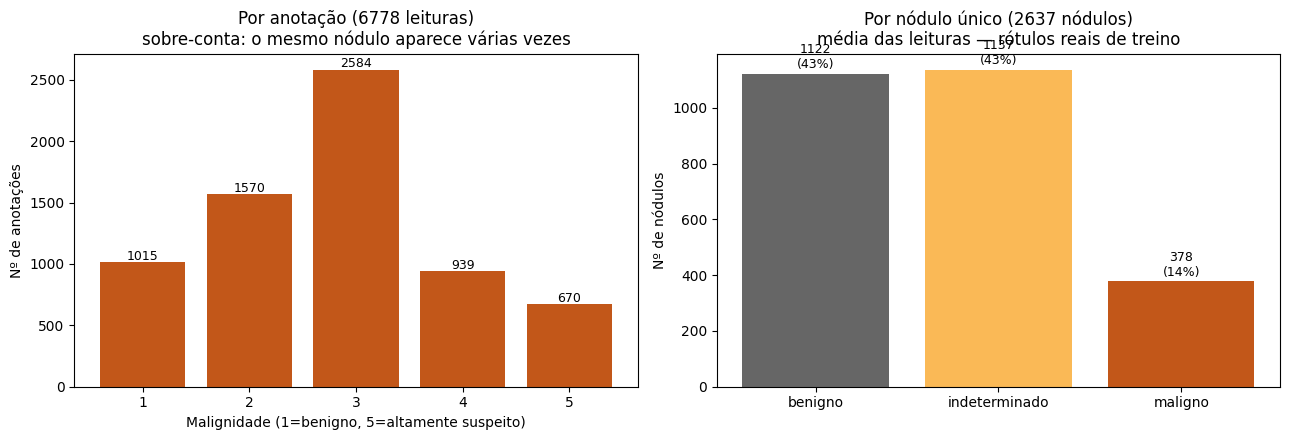

Nódulos únicos: 2637
Benignos (≤ 2.5):          1122 (43%)
Indeterminados (2.5-3.5):  1137 (43%)
Malignos (> 3.5):           378 (14%)


In [12]:
# --- Contagens por anotação (sobre-conta) ---
malignidades_anot = []
for scan in pl.query(pl.Scan):
    for cluster in cluster_annotations_silent(scan):
        if len(cluster) > 4:
            continue
        for ann in cluster:
            if ann.malignancy is not None:
                malignidades_anot.append(ann.malignancy)

dist_anot = pd.Series(malignidades_anot).value_counts().reindex([1, 2, 3, 4, 5]).fillna(0)

# --- Contagens por nódulo único (agregado) ---
malignidade_por_nodulo = []
for scan in pl.query(pl.Scan):
    for cluster in cluster_annotations_silent(scan):
        if len(cluster) > 4:
            continue
        ratings = [a.malignancy for a in cluster if a.malignancy is not None]
        if len(ratings) > 0:
            malignidade_por_nodulo.append(np.mean(ratings))
malignidade_por_nodulo = np.array(malignidade_por_nodulo)

def classificar(m):
    if m <= 2.5: return 'benigno'
    elif m <= 3.5: return 'indeterminado'
    else: return 'maligno'

contagem_nodulo = pd.Series([classificar(m) for m in malignidade_por_nodulo]).value_counts()
contagem_nodulo = contagem_nodulo.reindex(['benigno', 'indeterminado', 'maligno'])

# --- Plot lado a lado ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Esquerda: por anotação (sobre-conta)
bars0 = axes[0].bar(dist_anot.index, dist_anot.values, color='#c25719')
for bar, n in zip(bars0, dist_anot.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, n + 20,
                 f"{int(n)}", ha='center', fontsize=9)
axes[0].set_xticks([1, 2, 3, 4, 5])
axes[0].set_xlabel("Malignidade (1=benigno, 5=altamente suspeito)")
axes[0].set_ylabel("Nº de anotações")
axes[0].set_title(f"Por anotação ({sum(dist_anot.values):.0f} leituras)\n"
                  f"sobre-conta: o mesmo nódulo aparece várias vezes")

# Direita: por nódulo único (o que interessa)
cores = ['#666666', '#fab956', '#c25719']
bars1 = axes[1].bar(contagem_nodulo.index, contagem_nodulo.values, color=cores)
for bar, n in zip(bars1, contagem_nodulo.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, n + 20,
                 f"{n}\n({100*n/contagem_nodulo.sum():.0f}%)",
                 ha='center', fontsize=9)
axes[1].set_ylabel("Nº de nódulos")
axes[1].set_title(f"Por nódulo único ({len(malignidade_por_nodulo)} nódulos)\n"
                  f"média das leituras — rótulos reais de treino")

plt.tight_layout()
plt.show()

print(f"Nódulos únicos: {len(malignidade_por_nodulo)}")
print(f"Benignos (≤ 2.5):         {contagem_nodulo['benigno']:5d} ({100*contagem_nodulo['benigno']/contagem_nodulo.sum():.0f}%)")
print(f"Indeterminados (2.5-3.5): {contagem_nodulo['indeterminado']:5d} ({100*contagem_nodulo['indeterminado']/contagem_nodulo.sum():.0f}%)")
print(f"Malignos (> 3.5):         {contagem_nodulo['maligno']:5d} ({100*contagem_nodulo['maligno']/contagem_nodulo.sum():.0f}%)")

**Conclusão:** dos 2637 nódulos únicos do LIDC com malignidade avaliada, a distribuição ternária é bastante diferente do que o histograma por anotação sugeria. Após agregar as leituras por média, 1122 nódulos (43%) ficam classificados como benignos (média ≤ 2.5), 1137 (43%) como indeterminados (2.5–3.5) e apenas 378 (14%) como malignos (> 3.5).

**A observação central é a dimensão da classe indeterminada.** Quase metade dos nódulos cai na zona cinzenta, uma proporção muito superior à do LNDb, onde a classe intermédia era residual. A razão é dupla. Primeiro, o LIDC tem até 4 radiologistas por nódulo, contra 1–2 na maioria dos casos do LNDb; segundo, a agregação por média empurra para o meio qualquer nódulo onde os radiologistas divergem — duas leituras [2, 4] ou [1, 5] caem ambas em 3.0 e ficam indeterminadas. Uma fração substancial do indeterminado no LIDC não representa incerteza genuína dos radiologistas, representa dispersão entre eles.

**Implicações para o pipeline:**

**Descartar a classe indeterminada custaria quase metade do conjunto de treino.** Como discutido na secção de concordância (Lei et al., 2020; Zhang et al., 2022), esta classe não deve ser removida silenciosamente. Com 43% dos nódulos nesta zona, excluí-los reduziria o treino para ~1500 exemplos — menos de 60% do total — e enviesaria o modelo para os casos onde há consenso, que são precisamente os mais fáceis. A decisão de manter a classe ou de a usar em treino com uma função de perda ordinal tem de ser explícita.

**A prevalência de malignidade é maior no LIDC do que no LNDb.** Aqui, 14% dos nódulos classificam-se como malignos, contra 13% no LNDb (por leitura). A proporção é semelhante, mas a razão benigno:maligno é muito menor no LIDC — 3:1 aqui, contra 5:1 no LNDb — porque a classe indeterminada absorve a maioria dos casos que no LNDb seriam benignos. Isto significa que estratégias de class weights ou resampling pensadas para o LNDb podem não transferir diretamente.

## Parâmetros de aquisição

O LNDb é homogéneo (uma instituição, 3 modelos Siemens). O LIDC não: 7 instituições, vários fabricantes, vários protocolos. Isto afeta a distribuição de intensidades das imagens e, por consequência, as features extraídas.

**O que isto decide:** se é preciso normalização de intensidade mais agressiva, e se fabricante/modelo deve entrar como feature ou como variável de confundimento.

Scans com DICOM acessível:  883
Scans sem DICOM local:      135
Total:                      1018


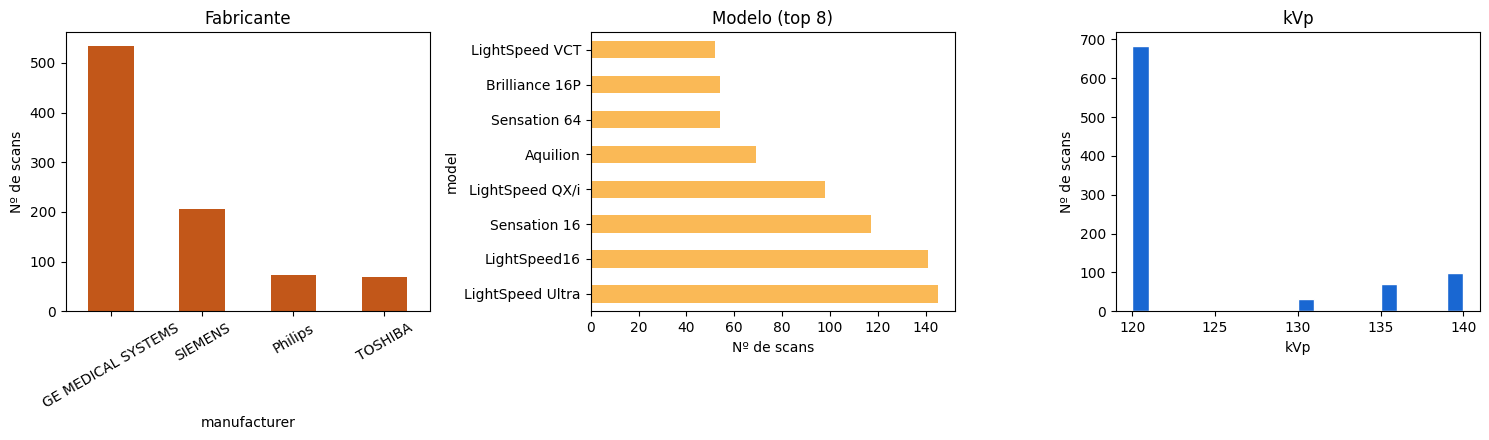


kVp: min=120, mediana=120, max=140


In [13]:
import pydicom
from pathlib import Path

TAGS_AQUISICAO = {
    'manufacturer':        'Manufacturer',
    'model':               'ManufacturerModelName',
    'kvp':                 'KVP',
    'exposure':            'Exposure',
    'convolution_kernel':  'ConvolutionKernel',
    'institution_name':    'InstitutionName',
}

def extrair_metadados_dicom(scan):
    """Lê o primeiro DICOM do scan. Devolve None se a pasta não existir ou estiver vazia."""
    try:
        dicom_dir = Path(scan.get_path_to_dicom_files())
    except Exception:
        return None
    dcm_files = sorted(dicom_dir.glob('*.dcm'))
    if not dcm_files:
        return None

    ds = pydicom.dcmread(str(dcm_files[0]), stop_before_pixels=True)
    resultado = {'patient_id': scan.patient_id}
    for nome_coluna, tag in TAGS_AQUISICAO.items():
        valor = getattr(ds, tag, None)
        if isinstance(valor, (list, tuple)):
            valor = str(valor[0]) if len(valor) > 0 else None
        resultado[nome_coluna] = valor
    return resultado

# Recolher, ignorando silenciosamente os scans sem DICOM
aquisicao = []
n_sem_dicom = 0
for scan in pl.query(pl.Scan):
    meta = extrair_metadados_dicom(scan)
    if meta is None:
        n_sem_dicom += 1
        continue
    aquisicao.append(meta)

df_aq = pd.DataFrame(aquisicao)
print(f"Scans com DICOM acessível:  {len(df_aq)}")
print(f"Scans sem DICOM local:      {n_sem_dicom}")
print(f"Total:                      {len(df_aq) + n_sem_dicom}")

# --- Gráficos ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

df_aq['manufacturer'].dropna().value_counts().plot(kind='bar', ax=axes[0], color='#c25719')
axes[0].set_title("Fabricante")
axes[0].set_ylabel("Nº de scans")
axes[0].tick_params(axis='x', rotation=30)

df_aq['model'].dropna().value_counts().head(8).plot(kind='barh', ax=axes[1], color='#fab956')
axes[1].set_title("Modelo (top 8)")
axes[1].set_xlabel("Nº de scans")

kvp_vals = pd.to_numeric(df_aq['kvp'], errors='coerce').dropna()
axes[2].hist(kvp_vals, bins=20, color='#1967d2', edgecolor='white')
axes[2].set_title("kVp")
axes[2].set_xlabel("kVp")
axes[2].set_ylabel("Nº de scans")

plt.tight_layout()
plt.show()

print(f"\nkVp: min={kvp_vals.min():.0f}, mediana={kvp_vals.median():.0f}, max={kvp_vals.max():.0f}")

vou esperar pelos resultados :)

## Decisão- Consensus de máscaras

Como discutido na secção 5, o LNDb tem uma máscara 3D por nódulo por radiologista, pré-computada. O LIDC não tem máscaras em ficheiro: tem contornos XML que o pylidc reconstrói em memória. Quando um nódulo tem mais do que um radiologista, temos de **decidir como produzir uma única máscara por nódulo**, porque o classificador não pode treinar em 4 máscaras diferentes para o mesmo nódulo.

Três opções possíveis:

| Método | Regra | Vantagem | Desvantagem |
|---|---|---|---|
| **Union** | voxel positivo se ≥1 radiologista o marcou | preserva todo o nódulo | sobre-estima o volume, inclui tecido normal |
| **Interseção** | voxel positivo se todos marcaram | conservador | máscara pode ficar vazia |
| **Voto por maioria** | voxel positivo se > 50% marcaram | equilíbrio, default da literatura | precisa de ≥2 radiologistas |

**Decisão tomada:** voto por maioria (`pylidc.utils.consensus()`), porque é o default da literatura e é o que melhor reflete "a opinião da maioria" quando há discordância. Nódulos com um só radiologista ficam com a máscara desse radiologista (não há consensus a fazer).

Loading dicom files ... This may take a moment.


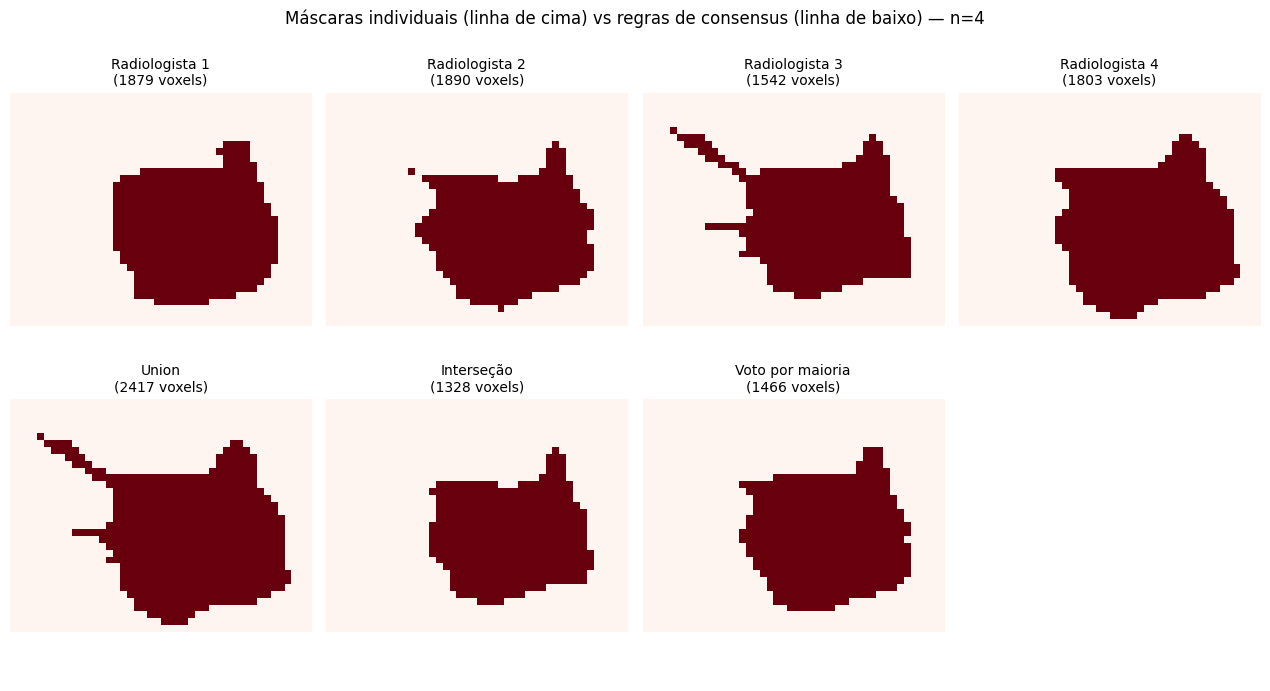

In [15]:
# Comparar as máscaras individuais e as três regras de consensus no mesmo nódulo.

# 1. Escolher o primeiro cluster com 2 a 4 anotações
exemplo_scan = None
exemplo_cluster = None
for scan in pl.query(pl.Scan):
    for cluster in cluster_annotations_silent(scan):
        if 2 <= len(cluster) <= 4:
            exemplo_scan, exemplo_cluster = scan, cluster
            break
    if exemplo_scan is not None:
        break

if exemplo_scan is None:
    print("Não foi encontrado nenhum nódulo com 2-4 anotações.")
else:
    # 2. Colocar cada máscara no sistema de coordenadas global do volume
    volume = exemplo_scan.to_volume()
    masks_globais = []
    for ann in exemplo_cluster:
        mask_global = np.zeros(volume.shape, dtype=bool)
        mask_global[ann.bbox()] = ann.boolean_mask()
        masks_globais.append(mask_global)

    # 3. Bounding box comum
    bboxes = [ann.bbox() for ann in exemplo_cluster]
    bbox_comum = tuple(
        slice(min(b[i].start for b in bboxes),
              max(b[i].stop  for b in bboxes))
        for i in range(3)
    )

    # 4. Três regras de consensus
    stack = np.stack(masks_globais, axis=0).astype(np.uint8)
    n = len(exemplo_cluster)

    mask_union    = stack.any(axis=0)
    mask_inter    = stack.all(axis=0)
    mask_majority = stack.sum(axis=0) > (n / 2)

    # 5. Recortar pela bbox comum
    masks_c         = [m[bbox_comum] for m in masks_globais]
    mask_union_c    = mask_union[bbox_comum]
    mask_inter_c    = mask_inter[bbox_comum]
    mask_majority_c = mask_majority[bbox_comum]

    fatia = mask_union_c.shape[2] // 2

    # 6. Gráfico em duas linhas
    n_cols = max(n, 3)
    fig, axes = plt.subplots(2, n_cols, figsize=(3.2 * n_cols, 7))

    # Linha 1: máscaras individuais
    for i, mask in enumerate(masks_c):
        ax = axes[0, i]
        ax.imshow(mask[:, :, fatia], cmap='Reds')
        ax.set_title(f"Radiologista {i+1}\n({mask.sum()} voxels)", fontsize=10)
        ax.axis('off')
    for j in range(n, n_cols):
        axes[0, j].axis('off')

    # Linha 2: regras de consensus
    regras = [
        (mask_union_c,    "Union"),
        (mask_inter_c,    "Interseção"),
        (mask_majority_c, "Voto por maioria"),
    ]
    for j, (mask, nome) in enumerate(regras):
        ax = axes[1, j]
        ax.imshow(mask[:, :, fatia], cmap='Reds')
        ax.set_title(f"{nome}\n({mask.sum()} voxels)", fontsize=10)
        ax.axis('off')
    for j in range(3, n_cols):
        axes[1, j].axis('off')

    plt.suptitle(f"Máscaras individuais (linha de cima) vs regras de consensus (linha de baixo) — n={n}",
                 fontsize=12)
    plt.tight_layout()
    plt.show()

**Conclusão:** as máscaras individuais (linha de cima) mostram que os quatro radiologistas discordam nos contornos mesmo para o mesmo nódulo físico — cada um desenha uma forma diferente em extensão e forma. As contagens confirmam-no: os radiologistas individuais produzem 1542–1890 voxels, a união 2417, a interseção 1328 e o voto por maioria 1466. A escolha da regra de consensus tem, por isso, impacto direto no volume final da máscara, e consequentemente em qualquer feature radiomica derivada do seu interior.

**A decisão sobre o threshold é a parte crítica.** O default da literatura é o **voto por maioria (≥50%)**, que é também o default do `pylidc` — a função `consensus` com `clevel=0.5` marca um voxel como positivo quando mais de metade dos radiologistas o marcaram (Carrazza et al., 2016; LA-ResUNet, 2024; AutoRad-Lung, 2025). Esta é a regra adotada neste projeto: com 4 radiologistas, um voxel é positivo se ≥3 concordarem, e com 2 ou 3 radiologistas o critério ajusta-se proporcionalmente.

**A alternativa é a união**, que maximiza recall ao incluir qualquer voxel marcado por pelo menos um radiologista. O estudo fundamental de Ross et al. (2007) comparou explicitamente união, interseção e STAPLE em 41 exames do LIDC e concluiu que *"using the union as the consensus scheme produced the greatest number of nodule-positive voxels while using the intersection produced the fewest"*. Isto significa que a união é a escolha correta quando o objetivo é maximizar sensibilidade — por exemplo, em tarefas de deteção onde perder um nódulo é mais grave do que incluir tecido adjacente. A interseção, por oposição, é a mais conservadora e pode produzir máscaras fragmentadas ou vazias quando os contornos discordam muito.

Para classificação de malignidade, o voto por maioria é o compromisso correto: não inflaciona o volume como a união (que inclui tecido perinodular marcado por um só radiologista) nem o reduz excessivamente como a interseção (que pode eliminar regiões de consenso parcial). A maioria fica próxima do radiologista médio em tamanho, o que é desejável para manter a comparabilidade com as features extraídas de anotações individuais.

**Nota:** para nódulos com apenas 1 anotação — que são ~29% do dataset, como visto na secção de cobertura — não há consensus a aplicar. A máscara é a do único radiologista, usada tal como está.

## Análise de Malignidade

## Diferenças relevantes LIDC-IDRI vs. LNDb

### Diferenças estruturais

| Aspeto | LIDC-IDRI | LNDb |
|---|---|---|
| **Nº de scans** | 1018 séries de TC | 294 séries |
| **Nº de instituições** | 7 | 1 (CHUSJ, Porto) |
| **Metodologia** | 4 radiólogos, 2 fases (blinded + unblinded) | 5 radiólogos, single-blind |
| **Identidade dos radiologistas** | Anónima, não rastreável entre scans | Rastreável (R1-R5 consistentes) |
| **Formato das imagens** | DICOM (.dcm) por fatia | MetaImage (.mhd/.raw) |
| **Formato das anotações** | XML (`LidcReadMessage`) com contornos por fatia | CSV com coordenadas 3D do centro + volume |
| **Segmentação** | Contornos 2D por fatia (é preciso reconstruir) | Máscara 3D pré-computada |
| **Volume do nódulo** | Calculado a partir do contorno | Fornecido diretamente (em mm³) |
| **Diâmetro** | Calculado (`annotation.diameter`) | Calculado por `nodEqDiam` a partir do volume |
| **Características subjetivas** | 9 (subtlety, internalStructure, calcification, sphericity, margin, lobulation, spiculation, texture, malignancy) | 7 (calcification, internalStructure, lobulation, malignancy, margin, sphericity, spiculation, subtlety) |
| **Conjunto de treino** | Não há split oficial | Split oficial `train`/`test` |
| **Aquisição** | Muito heterogénea (7 instituições, vários scanners) | Homogénea (1 instituição) |

### Implicações para o pipeline


1. Distribuição de labels por radiologista, não por nódulo.</strong> Se um nódulo tem 4 anotações e 3 radiólogos lhe deram malignidade = 2 e 1 deu = 3, a linha "oficial" não existe — temos de decidir como agregar (média, mediana, maioria, ou manter as 4 linhas separadas como no LNDb).

2. **A máscara é 3D mas esparsa.** No LNDb a máscara é um volume binário denso. No LIDC, `ann.boolean_mask()` devolve uma máscara no bounding box — o pipeline tem de lidar com ambas.

3. **Contornos têm de ser fundidos.** Se quisermos uma máscara "de consenso" (como no LNDb, em que há uma máscara por nódulo), temos de aplicar `pl.utils.consensus()` ou uma regra de maioria.

4. **Não há `RadID` estável.** Não vai ser possível usar o radiologista como feature.

5. **Escalas diferentes.** No LNDb, os valores de `malignancy` vêm diretamente do CSV. No LIDC, `pylidc` normaliza.

6. Ficheiros XML duplicados.</strong> O pacote oficial contém, para cada série de TC, um XML de TC (<code>LidcReadMessage</code>) e frequentemente um XML de radiografia de tórax (<code>IdriReadMessage</code>). O <code>pylidc</code> <strong>só processa os XMLs de TC</strong>.


### Atenção

Para aceder ao volume é preciso ter as imagens DICOM em disco e configurar o `pylidcrc` com o caminho correto. No LNDb, o `utils.py` lê diretamente o `.mhd`. Além disso, ao contrário do LNDb (que fornece volumes pré-computados em MetaImage), o LIDC-IDRI guarda os contornos como sequências de pontos <code>(x, y, z)</code> por fatia. O volume tem de ser reconstruído.

Cada radiologista marcou as lesões em três categorias: <em>nódulo ≥ 3 mm</em>, <em>nódulo &lt; 3 mm</em>, e <em>não-nódulo ≥ 3 mm</em>. Apenas nódulos ≥ 3 mm têm contornos 3D e as 9 características subjetivas.

## Bases ciencítificas 

- Armato, S. G., et al. (2011). The Lung Image Database Consortium (LIDC) and Image Database Resource Initiative (IDRI): A completed reference database of lung nodules on CT scans. Medical Physics, 38(2), 915–931. - https://staging.europepmc.org/article/MED/21452728#free-full-text#4-  define o critério de 3 mm do LIDC como o maior diâmetro in-plane e nota que o diâmetro reconstruído pode ser inferior, justificando os 5 casos abaixo do limiar.

- Yang, Y., et al. (2023). Attention-guided deep neural network with a multichannel architecture for lung nodule classification. Heliyon. — justifica a estratégia multiescala pela variação de tamanhos de nódulos no LIDC-IDRI.

- Ross, J. C., Miller, J. V., Turner, W. D., & Kelliher, T. P. (2007). *An analysis of early studies released by the Lung Imaging Database Consortium (LIDC)*. Academic Radiology, 14(11), 1382–1388. — compara esquemas de consensus (união, interseção, STAPLE) em 41 exames do LIDC e conclui que a união produz o maior número de voxels positivos e a interseção o menor.
- Carrazza, M., Kennedy, B., Rasin, A., Furst, J., & Raicu, D. (2016). *Investigating the effects of majority voting on CAD systems: A LIDC case study*. Medical Imaging 2016: Computer-Aided Diagnosis, SPIE. — investiga os efeitos do majority voting em sistemas CAD treinados no LIDC, mostrando que a escolha da regra de agregação afeta significativamente o desempenho.
- LA-ResUNet (2024). *An Efficient Linear Attention Mechanism in ResUNet for the Semantic Segmentation of Pulmonary Nodules*. IEEE. — usa a função `consensus` do `pylidc` com 50% de consenso entre radiologistas para gerar a máscara de ground truth.
- AutoRad-Lung (2025). arXiv:2503.20662. — define o boundary do nódulo "only if at least 50% of the annotators agree", usando consensus-based mask para extração de features radiomicas.